## PART A - TASK 2: DATA GATHERING, AUDIT AND PREPARATION

In [ ]:

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

CSV = 'healthcare-dataset-stroke-data.csv'
if not os.path.exists(CSV):
    try:
        from google.colab import files
        print('Choose the file healthcare-dataset-stroke-data.csv from your computer...')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Put healthcare-dataset-stroke-data.csv in the same folder as this notebook.')

df = pd.read_csv(CSV)

print('Shape (rows, columns):', df.shape)
print()
display(df.head())
print()
df.info()

Shape (rows, columns): (5110, 12)



,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:

print()
miss = df.isnull().sum()
audit = pd.DataFrame({'missing': miss, 'percent_missing': (miss / len(df) * 100).round(2)})
print('Missing values per column:')
display(audit)
print('Duplicate rows:', df.duplicated().sum())
print()
print('Target (stroke) counts:')
print(df['stroke'].value_counts().rename({0: '0 = no stroke', 1: '1 = stroke'}))
print('Stroke percentage: %.2f%%' % (df['stroke'].mean() * 100))
print('Stroke cases among patients with MISSING bmi: %d of %d' % (df.loc[df['bmi'].isnull(), 'stroke'].sum(), df['bmi'].isnull().sum()))
print()
print('gender values       :', df['gender'].value_counts().to_dict())
print('smoking_status      :', df['smoking_status'].value_counts().to_dict())
print()
print('Numeric summary:')
display(df[['age', 'avg_glucose_level', 'bmi']].describe().round(2))


Missing values per column:


,missing,percent_missing
id,0,0.00
gender,0,0.00
age,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
ever_married,0,0.00
work_type,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00
bmi,201,3.93


Duplicate rows: 0

Target (stroke) counts:
stroke
0 = no stroke    4861
1 = stroke        249
Name: count, dtype: int64
Stroke percentage: 4.87%
Stroke cases among patients with MISSING bmi: 40 of 201

gender values       : {'Female': 2994, 'Male': 2115, 'Other': 1}
smoking_status      : {'never smoked': 1892, 'Unknown': 1544, 'formerly smoked': 885, 'smokes': 789}

Numeric summary:


,age,avg_glucose_level,bmi
count,5110.00,5110.00,4909.00
mean,43.23,106.15,28.89
std,22.61,45.28,7.85
min,0.08,55.12,10.30
25%,25.00,77.24,23.50
50%,45.00,91.88,28.10
75%,61.00,114.09,33.10
max,82.00,271.74,97.60


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

df_work = df.drop(columns=['id'])                      # identifier: no predictive value
n_other = int((df_work['gender'] == 'Other').sum())
df_work = df_work[df_work['gender'] != 'Other'].reset_index(drop=True)   # one record only

X = df_work.drop(columns='stroke')
y = df_work['stroke']

# Split BEFORE imputing/scaling so no information from the test set leaks into training
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
cw = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)


print('Dropped column: id | Removed rows with gender = Other:', n_other)
print('Rows kept:', len(df_work))
print('Training set:', X_train.shape, '| Test set:', X_test.shape)
print('Test set stroke cases:', int(y_test.sum()), 'of', len(y_test))
print('Training class ratio  no-stroke : stroke = %d : %d  (%.1f : 1)' % (n0, n1, n0 / n1))
print('Balanced class weights  ->  class 0 = %.2f, class 1 = %.2f' % (cw[0], cw[1]))
print("Dummy 'always No Stroke' accuracy on test set: %.2f%%" % ((y_test == 0).mean() * 100))

Dropped column: id | Removed rows with gender = Other: 1
Rows kept: 5109
Training set: (4087, 10) | Test set: (1022, 10)
Test set stroke cases: 50 of 1022
Training class ratio  no-stroke : stroke = 3888 : 199  (19.5 : 1)
Balanced class weights  ->  class 0 = 0.53, class 1 = 10.27
Dummy 'always No Stroke' accuracy on test set: 95.11%


In [ ]:
#  BMI imputation using gender-grouped median
print('BMI imputation')
print('BMI missing BEFORE -> train:', int(X_train['bmi'].isnull().sum()),
      '| test:', int(X_test['bmi'].isnull().sum()))

# medians are learned from the TRAINING data only, then applied to both sets
bmi_medians = X_train.groupby('gender')['bmi'].median()
print('\nGender-grouped BMI medians (from training data):')
print(bmi_medians.round(2).to_string())

X_train_imp = X_train.copy()
X_test_imp = X_test.copy()
for part in (X_train_imp, X_test_imp):
    part['bmi'] = part['bmi'].fillna(part['gender'].map(bmi_medians))

print('\nBMI missing AFTER  -> train:', int(X_train_imp['bmi'].isnull().sum()),
      '| test:', int(X_test_imp['bmi'].isnull().sum()))

BMI imputation
BMI missing BEFORE -> train: 163 | test: 38

Gender-grouped BMI medians (from training data):
gender
Female    27.9
Male      28.3

BMI missing AFTER  -> train: 0 | test: 0


Class distribution and BMI distribution


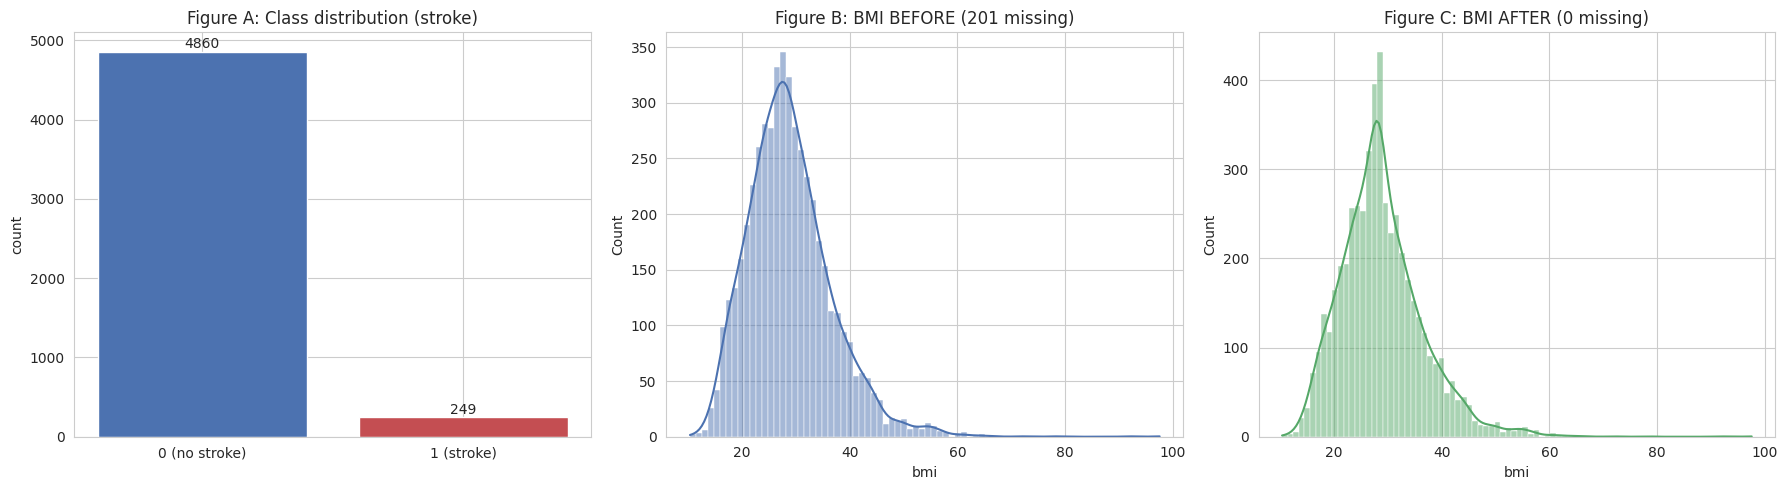

In [ ]:
#Class distribution + BMI before/after
print('Class distribution and BMI distribution')
bmi_before = df_work['bmi']
bmi_after = pd.concat([X_train_imp['bmi'], X_test_imp['bmi']])

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
counts = y.value_counts().sort_index()
bars = ax[0].bar(['0 (no stroke)', '1 (stroke)'], counts.values, color=['#4C72B0', '#C44E52'])
for b, v in zip(bars, counts.values):
    ax[0].text(b.get_x() + b.get_width() / 2, v + 40, str(v), ha='center')
ax[0].set_title('Figure A: Class distribution (stroke)')
ax[0].set_ylabel('count')

sns.histplot(bmi_before.dropna(), kde=True, color='#4C72B0', ax=ax[1])
ax[1].set_title('Figure B: BMI BEFORE (%d missing)' % bmi_before.isnull().sum())
ax[1].set_xlabel('bmi')

sns.histplot(bmi_after, kde=True, color='#55A868', ax=ax[2])
ax[2].set_title('Figure C: BMI AFTER (%d missing)' % bmi_after.isnull().sum())
ax[2].set_xlabel('bmi')

plt.tight_layout()
plt.savefig('task2_before_after.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
#  One-hot encoding of categorical variables
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ['age', 'avg_glucose_level', 'bmi']
bin_cols = ['hypertension', 'heart_disease']          # already 0/1
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

print('Encoding categorical variables')
print('BEFORE (text categories):')
display(X_train_imp[cat_cols].head())

encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
enc_train = pd.DataFrame(encoder.fit_transform(X_train_imp[cat_cols]),
                         columns=encoder.get_feature_names_out(cat_cols),
                         index=X_train_imp.index)
enc_test = pd.DataFrame(encoder.transform(X_test_imp[cat_cols]),
                        columns=encoder.get_feature_names_out(cat_cols),
                        index=X_test_imp.index)
print('AFTER (one-hot, first category dropped):')
display(enc_train.head().astype(int))
print('Number of encoded columns:', enc_train.shape[1])
print('Dropped (reference) categories:', {c: encoder.categories_[i][0] for i, c in enumerate(cat_cols)})

Encoding categorical variables
BEFORE (text categories):


,gender,ever_married,work_type,Residence_type,smoking_status
845,Female,Yes,Private,Urban,never smoked
3744,Female,No,Private,Urban,never smoked
4183,Female,Yes,Private,Rural,never smoked
3409,Male,Yes,Private,Rural,never smoked
284,Male,No,Govt_job,Urban,Unknown


AFTER (one-hot, first category dropped):


,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
845,0,1,0,1,0,0,1,0,1,0
3744,0,0,0,1,0,0,1,0,1,0
4183,0,1,0,1,0,0,0,0,1,0
3409,1,1,0,1,0,0,0,0,1,0
284,1,0,0,0,0,0,1,0,0,0


Number of encoded columns: 10
Dropped (reference) categories: {'gender': 'Female', 'ever_married': 'No', 'work_type': 'Govt_job', 'Residence_type': 'Rural', 'smoking_status': 'Unknown'}


In [ ]:
#Feature scaling
print('Feature scaling (StandardScaler, fitted on training data only)')
print('BEFORE scaling (training set):')
display(X_train_imp[num_cols].describe().loc[['mean', 'std', 'min', 'max']].round(2))

scaler = StandardScaler()
sc_train = pd.DataFrame(scaler.fit_transform(X_train_imp[num_cols]), columns=num_cols, index=X_train_imp.index)
sc_test = pd.DataFrame(scaler.transform(X_test_imp[num_cols]), columns=num_cols, index=X_test_imp.index)

print('AFTER scaling (training set):')
display(sc_train.describe().loc[['mean', 'std', 'min', 'max']].round(2))


X_train_final = pd.concat([sc_train, X_train_imp[bin_cols], enc_train], axis=1)
X_test_final = pd.concat([sc_test, X_test_imp[bin_cols], enc_test], axis=1)
feature_names = list(X_train_final.columns)
print('Final feature matrix  -> train:', X_train_final.shape, '| test:', X_test_final.shape)

Feature scaling (StandardScaler, fitted on training data only)
BEFORE scaling (training set):


,age,avg_glucose_level,bmi
mean,43.26,105.90,28.85
std,22.64,44.68,7.74
min,0.08,55.22,10.30
max,82.00,271.74,97.60


AFTER scaling (training set):


,age,avg_glucose_level,bmi
mean,-0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.91,-1.13,-2.40
max,1.71,3.71,8.89


Final feature matrix  -> train: (4087, 15) | test: (1022, 15)


Quality check


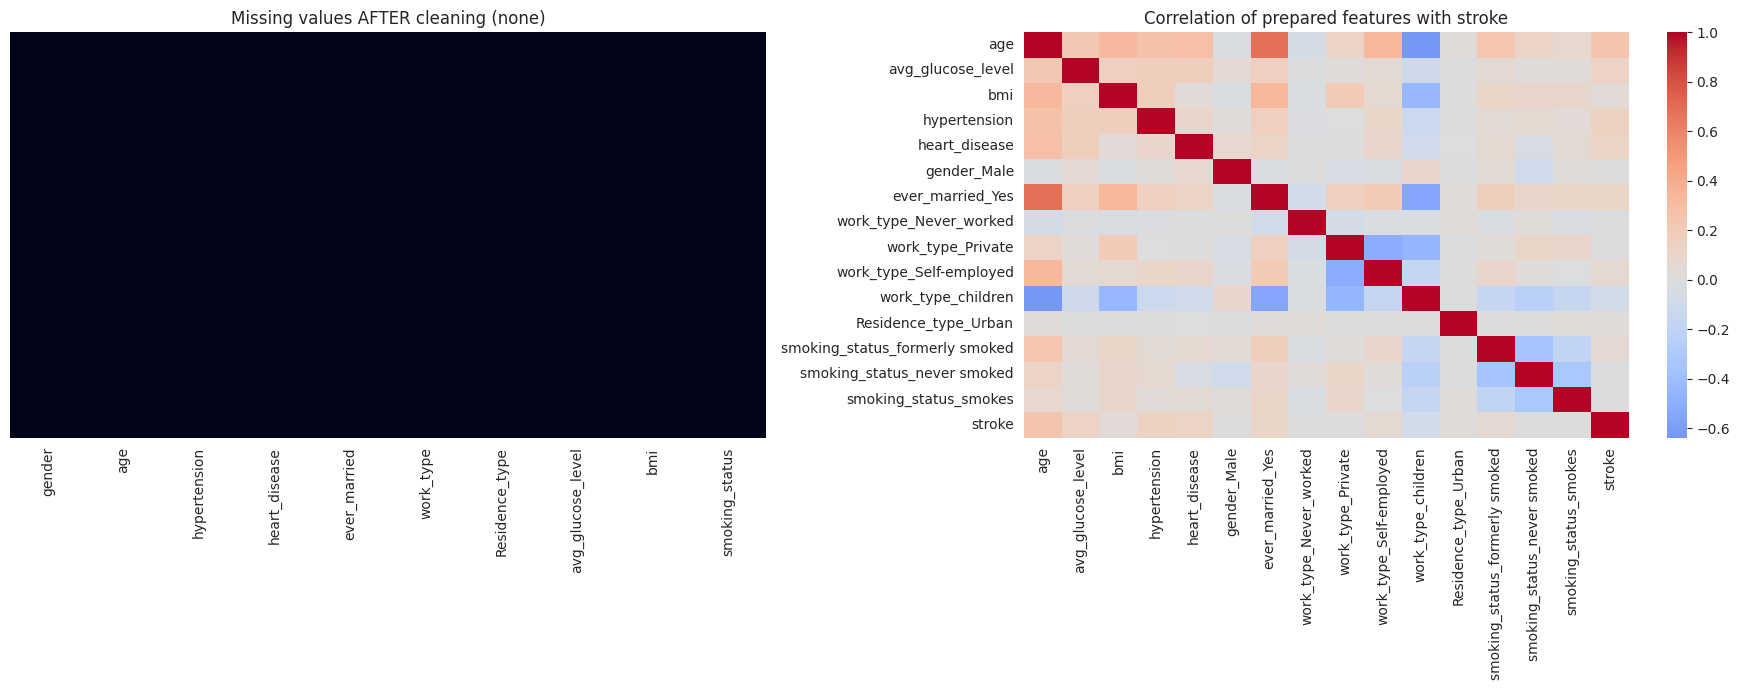

Total missing values remaining: 0

Correlation of each feature with stroke (largest first):
age                               0.244
hypertension                      0.137
avg_glucose_level                 0.129
heart_disease                     0.121
ever_married_Yes                  0.107
work_type_Self-employed           0.070
smoking_status_formerly smoked    0.063
bmi                               0.037
Residence_type_Urban              0.018
smoking_status_smokes             0.013
gender_Male                       0.011
work_type_Private                 0.004
smoking_status_never smoked      -0.007
work_type_Never_worked           -0.014
work_type_children               -0.086

Saved: cleaned_train.csv, cleaned_test.csv, task2_before_after.png, task2_quality_check.png


In [ ]:
#Quality check after cleaning
print('Quality check')
df_clean = pd.concat([X_train_imp, X_test_imp])        # dataset AFTER imputation
prepared = pd.concat([X_train_final.reset_index(drop=True),
                      y_train.reset_index(drop=True)], axis=1)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(df_clean.isnull(), cbar=False, yticklabels=False, ax=ax[0])
ax[0].set_title('Missing values AFTER cleaning (none)')
sns.heatmap(prepared.corr(), cmap='coolwarm', center=0, ax=ax[1])
ax[1].set_title('Correlation of prepared features with stroke')
ax[1].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.savefig('task2_quality_check.png', dpi=150, bbox_inches='tight')
plt.show()

print('Total missing values remaining:', int(df_clean.isnull().sum().sum()))
print('\nCorrelation of each feature with stroke (largest first):')
print(prepared.corr()['stroke'].drop('stroke').sort_values(ascending=False).round(3).to_string())

pd.concat([X_train_final, y_train], axis=1).to_csv('cleaned_train.csv', index=False)
pd.concat([X_test_final, y_test], axis=1).to_csv('cleaned_test.csv', index=False)
print('\nSaved: cleaned_train.csv, cleaned_test.csv, task2_before_after.png, task2_quality_check.png')

## PART B - TASK 3: BUILD, TEST AND EVALUATE THE MODEL

In [ ]:
#Train the three models
from sklearn.linear_model import LogisticRegression

models = {
    'Baseline (no weights, C=1.0)':   LogisticRegression(max_iter=1000, random_state=42),
    'Weighted (balanced, C=1.0)':     LogisticRegression(class_weight='balanced', C=1.0, max_iter=1000, random_state=42),
    'Optimised (balanced, C=0.4)':    LogisticRegression(class_weight='balanced', C=0.4, max_iter=1000, random_state=42),
}

print('Model training log')
print('Training rows: %d | Features: %d | Stroke cases in training: %d\n' % (
    X_train_final.shape[0], X_train_final.shape[1], int(y_train.sum())))
for name, model in models.items():
    model.fit(X_train_final, y_train)
    print('Trained  %-30s class_weight=%-9s C=%-4s iterations used=%d' % (
        name, model.class_weight, model.C, model.n_iter_[0]))
print('\nAll three models trained successfully.')

Model training log
Training rows: 4087 | Features: 15 | Stroke cases in training: 199

Trained  Baseline (no weights, C=1.0)   class_weight=None      C=1.0  iterations used=25
Trained  Weighted (balanced, C=1.0)     class_weight=balanced  C=1.0  iterations used=22
Trained  Optimised (balanced, C=0.4)    class_weight=balanced  C=0.4  iterations used=24

All three models trained successfully.


In [ ]:
#Cross-validation to check the regularisation strength C
from sklearn.model_selection import StratifiedKFold, cross_validate

print('5-fold stratified cross-validation (training data only)')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for C in [0.01, 0.05, 0.1, 0.4, 1.0, 10.0]:
    lr = LogisticRegression(class_weight='balanced', C=C, max_iter=1000, random_state=42)
    cv = cross_validate(lr, X_train_final, y_train, cv=skf, scoring=['recall', 'precision', 'roc_auc'])
    rows.append({'C': C,
                 'mean recall': cv['test_recall'].mean(),
                 'mean precision': cv['test_precision'].mean(),
                 'mean ROC-AUC': cv['test_roc_auc'].mean()})
cv_table = pd.DataFrame(rows).round(3)
display(cv_table)
print('Selected for the final model: C = 0.4 (value specified in the project brief; table shows it sits in the stable range).')

5-fold stratified cross-validation (training data only)


,C,mean recall,mean precision,mean ROC-AUC
0,0.01,0.814,0.132,0.840
1,0.05,0.799,0.134,0.840
2,0.10,0.799,0.134,0.840
3,0.40,0.819,0.138,0.839
4,1.00,0.819,0.139,0.839
5,10.00,0.819,0.139,0.839


Selected for the final model: C = 0.4 (value specified in the project brief; table shows it sits in the stable range).


In [ ]:
#Test-set results and success-criteria check
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             accuracy_score, precision_score, recall_score, f1_score)

results, preds, probas = [], {}, {}
print('Evaluation on the unseen test set (%d patients, %d strokes)' % (len(y_test), y_test.sum()))
for name, model in models.items():
    p = model.predict(X_test_final)
    pr = model.predict_proba(X_test_final)[:, 1]
    preds[name], probas[name] = p, pr
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    results.append({'Model': name,
                    'Accuracy': accuracy_score(y_test, p),
                    'Precision': precision_score(y_test, p, zero_division=0),
                    'Recall': recall_score(y_test, p),
                    'F1': f1_score(y_test, p, zero_division=0),
                    'ROC-AUC': roc_auc_score(y_test, pr),
                    'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
res = pd.DataFrame(results).set_index('Model')
res.round(4).to_csv('model_comparison.csv')

print('\n--- BASELINE ---')
print(classification_report(y_test, preds['Baseline (no weights, C=1.0)'], zero_division=0))
print('--- OPTIMISED (balanced, C=0.4) ---')
print(classification_report(y_test, preds['Optimised (balanced, C=0.4)'], zero_division=0))
print('--- COMPARISON TABLE (copy these numbers into Tables 13 and 14 of the report) ---')
display(res.round(3))

opt = res.loc['Optimised (balanced, C=0.4)']
print('SUCCESS CRITERIA CHECK (Optimised model)')
print('  Recall    >= 0.70 :', round(opt['Recall'], 3),    '->', 'MET' if opt['Recall'] >= 0.70 else 'NOT MET')
print('  ROC-AUC   >= 0.75 :', round(opt['ROC-AUC'], 3),   '->', 'MET' if opt['ROC-AUC'] >= 0.75 else 'NOT MET')
print('  Precision >= 0.10 :', round(opt['Precision'], 3), '->', 'MET' if opt['Precision'] >= 0.10 else 'NOT MET')
print('  Accuracy  >= 0.70 :', round(opt['Accuracy'], 3),  '->', 'MET' if opt['Accuracy'] >= 0.70 else 'NOT MET')

Evaluation on the unseen test set (1022 patients, 50 strokes)

--- BASELINE ---
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022

--- OPTIMISED (balanced, C=0.4) ---
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.53      1022
weighted avg       0.94      0.74      0.81      1022

--- COMPARISON TABLE (copy these numbers into Tables 13 and 14 of the report) ---


,Accuracy,Precision,Recall,F1,ROC-AUC,TN,FP,FN,TP
Model,,,,,,,,,
"Baseline (no weights, C=1.0)",0.952,1.000,0.02,0.039,0.839,972,0,49,1
"Weighted (balanced, C=1.0)",0.739,0.135,0.80,0.231,0.839,715,257,10,40
"Optimised (balanced, C=0.4)",0.736,0.133,0.80,0.229,0.839,712,260,10,40


SUCCESS CRITERIA CHECK (Optimised model)
  Recall    >= 0.70 : 0.8 -> MET
  ROC-AUC   >= 0.75 : 0.839 -> MET
  Precision >= 0.10 : 0.133 -> MET
  Accuracy  >= 0.70 : 0.736 -> MET


Confusion matrixes


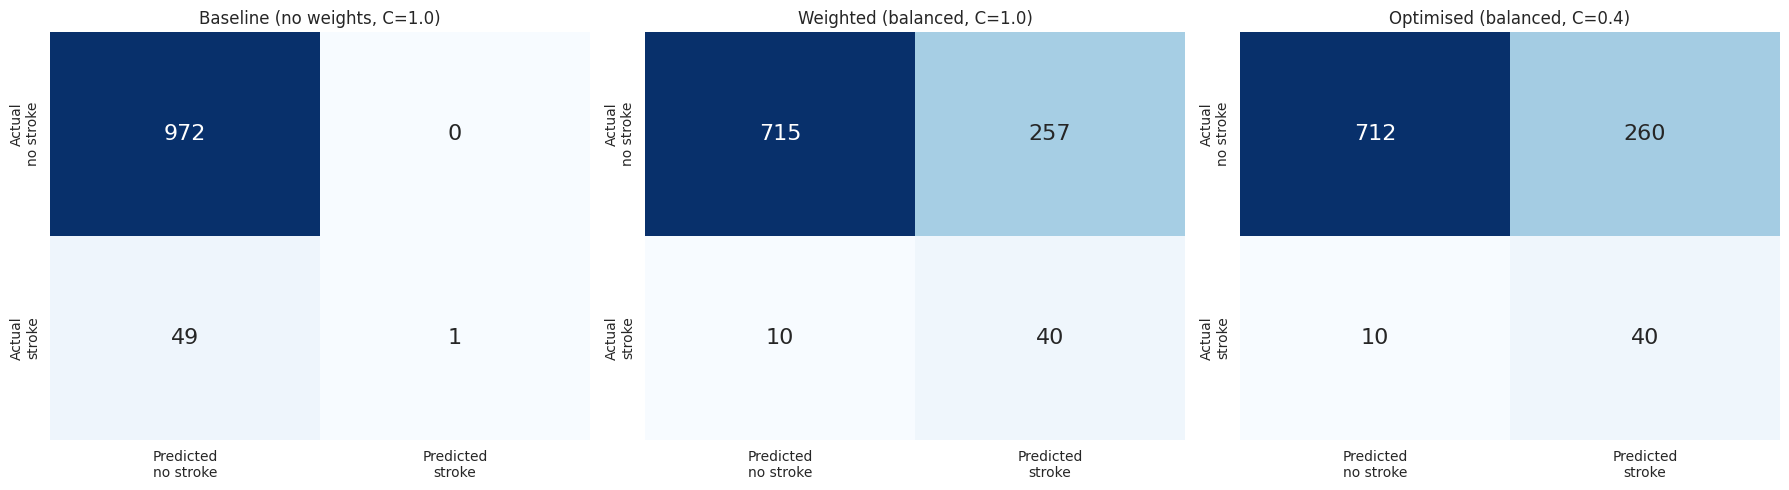

In [ ]:
#Confusion matrixes
print('Confusion matrixes')
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (name, p) in zip(ax, preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={'size': 16}, ax=a,
                xticklabels=['Predicted\nno stroke', 'Predicted\nstroke'],
                yticklabels=['Actual\nno stroke', 'Actual\nstroke'])
    a.set_title(name)
plt.tight_layout()
plt.savefig('task3_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

ROC and precision-recall curves


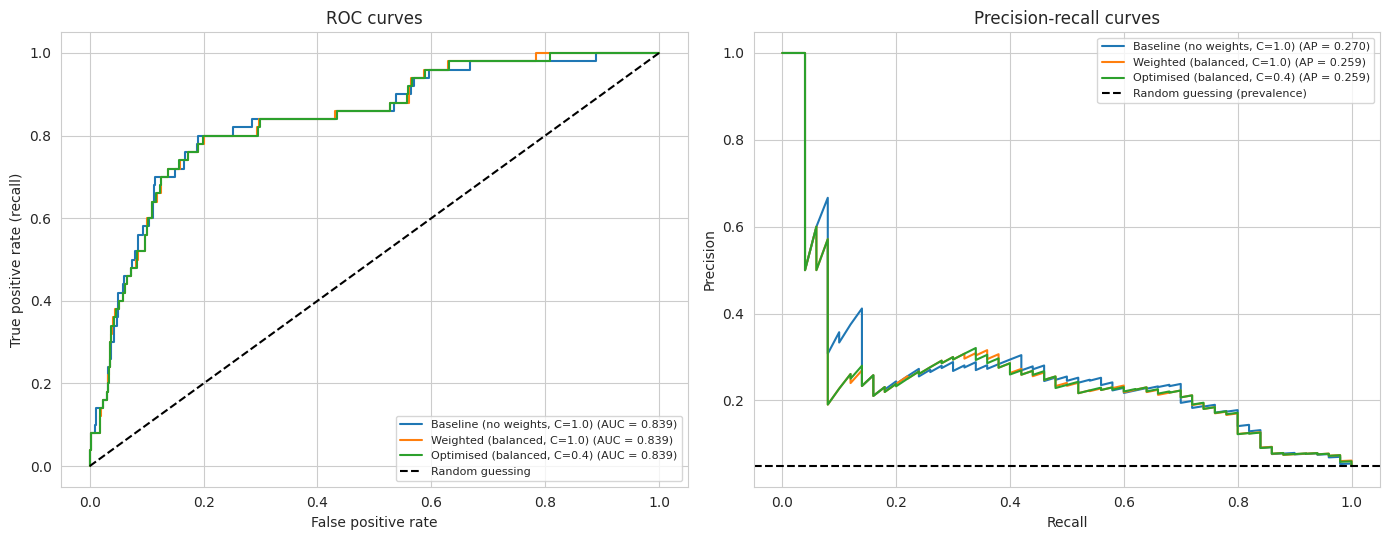

In [ ]:
#ROC and precision-recall curves
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

print('ROC and precision-recall curves')
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for name, pr in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    ax[0].plot(fpr, tpr, label='%s (AUC = %.3f)' % (name, roc_auc_score(y_test, pr)))
    prec, rec, _ = precision_recall_curve(y_test, pr)
    ax[1].plot(rec, prec, label='%s (AP = %.3f)' % (name, average_precision_score(y_test, pr)))
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guessing')
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate (recall)')
ax[0].set_title('ROC curves'); ax[0].legend(loc='lower right', fontsize=8)
ax[1].axhline(y_test.mean(), color='k', linestyle='--', label='Random guessing (prevalence)')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-recall curves'); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('task3_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

 Model coefficients (age, glucose and BMI are standardised: odds ratio = per 1 standard deviation)


,feature,coefficient,odds_ratio
0,age,1.855,6.390
1,work_type_children,0.696,2.005
2,hypertension,0.619,1.858
3,smoking_status_smokes,0.270,1.310
4,avg_glucose_level,0.213,1.237
5,Residence_type_Urban,0.173,1.189
6,heart_disease,0.149,1.161
7,smoking_status_formerly smoked,0.085,1.089
8,bmi,0.053,1.054
9,work_type_Private,0.020,1.020


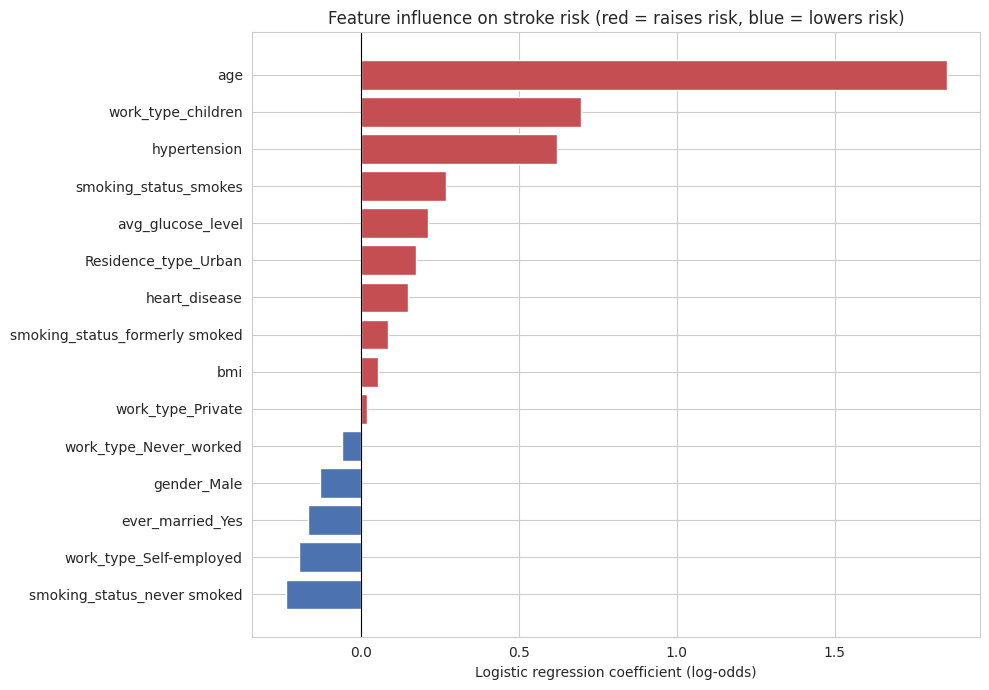

HYPOTHESIS CHECK
  H1  age coefficient > 0               : True (1.855)
  H1  avg_glucose_level coefficient > 0  : True (0.213)
  H2  hypertension coefficient > 0       : True (0.619)
  H2  heart_disease coefficient > 0      : True (0.149)


In [ ]:
#Coefficients / odds ratios - explainability and hypothesis test
final_model = models['Optimised (balanced, C=0.4)']
coef = pd.DataFrame({'feature': feature_names,
                     'coefficient': final_model.coef_[0],
                     'odds_ratio': np.exp(final_model.coef_[0])}).sort_values('coefficient', ascending=False)

print(' Model coefficients (age, glucose and BMI are standardised: odds ratio = per 1 standard deviation)')
display(coef.round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in coef['coefficient']]
ax.barh(coef['feature'][::-1], coef['coefficient'][::-1], color=colors[::-1])
ax.axvline(0, color='k', linewidth=0.8)
ax.set_xlabel('Logistic regression coefficient (log-odds)')
ax.set_title('Feature influence on stroke risk (red = raises risk, blue = lowers risk)')
plt.tight_layout()
plt.savefig('task3_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

c = coef.set_index('feature')['coefficient']
print('HYPOTHESIS CHECK')
print('  H1  age coefficient > 0               :', bool(c['age'] > 0), '(%.3f)' % c['age'])
print('  H1  avg_glucose_level coefficient > 0  :', bool(c['avg_glucose_level'] > 0), '(%.3f)' % c['avg_glucose_level'])
print('  H2  hypertension coefficient > 0       :', bool(c['hypertension'] > 0), '(%.3f)' % c['hypertension'])
print('  H2  heart_disease coefficient > 0      :', bool(c['heart_disease'] > 0), '(%.3f)' % c['heart_disease'])

In [ ]:
#Deploy and use: predict for new patients
import joblib

def prepare_new_patients(raw):
    """Apply the SAME cleaning steps that were fitted on the training data."""
    raw = raw.copy()
    raw['bmi'] = raw['bmi'].fillna(raw['gender'].map(bmi_medians))
    sc = pd.DataFrame(scaler.transform(raw[num_cols]), columns=num_cols, index=raw.index)
    en = pd.DataFrame(encoder.transform(raw[cat_cols]), columns=encoder.get_feature_names_out(cat_cols), index=raw.index)
    return pd.concat([sc, raw[bin_cols], en], axis=1)[feature_names]

def predict_stroke_risk(patients, threshold=0.5):
    X_new = prepare_new_patients(pd.DataFrame(patients))
    score = final_model.predict_proba(X_new)[:, 1]
    out = pd.DataFrame(patients)[['age', 'gender', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']].copy()
    out['risk_score'] = score.round(3)
    out['decision'] = np.where(score >= threshold, 'REFER for further assessment', 'Routine care')
    return out

joblib.dump({'model': final_model, 'bmi_medians': bmi_medians, 'encoder': encoder,
             'scaler': scaler, 'feature_names': feature_names}, 'stroke_model.joblib')

new_patients = [
    {'gender': 'Female', 'age': 25, 'hypertension': 0, 'heart_disease': 0, 'ever_married': 'No',
     'work_type': 'Private', 'Residence_type': 'Urban', 'avg_glucose_level': 85.0, 'bmi': 22.0, 'smoking_status': 'never smoked'},
    {'gender': 'Male', 'age': 55, 'hypertension': 1, 'heart_disease': 0, 'ever_married': 'Yes',
     'work_type': 'Self-employed', 'Residence_type': 'Rural', 'avg_glucose_level': 130.0, 'bmi': np.nan, 'smoking_status': 'formerly smoked'},
    {'gender': 'Female', 'age': 78, 'hypertension': 1, 'heart_disease': 1, 'ever_married': 'Yes',
     'work_type': 'Private', 'Residence_type': 'Urban', 'avg_glucose_level': 220.0, 'bmi': 34.0, 'smoking_status': 'smokes'},
]
print('Model saved as stroke_model.joblib and used on three new patients')
print('(Patient 2 has a missing BMI - it is filled automatically with the gender median.)\n')
display(predict_stroke_risk(new_patients))
print('NOTE: risk_score is a ranking score from a class-weighted model, not a true probability of stroke.')

Model saved as stroke_model.joblib and used on three new patients
(Patient 2 has a missing BMI - it is filled automatically with the gender median.)



,age,gender,hypertension,heart_disease,avg_glucose_level,bmi,risk_score,decision
0,25,Female,0,0,85.0,22.0,0.053,Routine care
1,55,Male,1,0,130.0,NaN,0.520,REFER for further assessment
2,78,Female,1,1,220.0,34.0,0.964,REFER for further assessment


NOTE: risk_score is a ranking score from a class-weighted model, not a true probability of stroke.


In [ ]:
#Threshold exploration - suggested improvement
print('Effect of changing the decision threshold (Optimised model)')
pr = probas['Optimised (balanced, C=0.4)']
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    flag = (pr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
    rows.append({'threshold': t, 'patients flagged': int(flag.sum()),
                 'strokes caught (TP)': tp, 'strokes missed (FN)': fn, 'false alarms (FP)': fp,
                 'recall': round(tp / (tp + fn), 3),
                 'precision': round(tp / (tp + fp), 3) if (tp + fp) else 0.0})
display(pd.DataFrame(rows))

Effect of changing the decision threshold (Optimised model)


,threshold,patients flagged,strokes caught (TP),strokes missed (FN),false alarms (FP),recall,precision
0,0.3,453,42,8,411,0.84,0.093
1,0.4,374,42,8,332,0.84,0.112
2,0.5,300,40,10,260,0.80,0.133
3,0.6,223,39,11,184,0.78,0.175
4,0.7,178,36,14,142,0.72,0.202
5,0.8,101,24,26,77,0.48,0.238


In [ ]:
# Environment versions
import sklearn, matplotlib
print('Library versions used in this run:')
for lib in (pd, np, sklearn, matplotlib, sns, joblib):
    print('%-14s %s' % (lib.__name__, lib.__version__))

Library versions used in this run:
pandas         2.2.3
numpy          2.4.6
sklearn        1.6.1
matplotlib     3.10.0
seaborn        0.13.2
joblib         1.6.0
